<a href="https://colab.research.google.com/github/gguex/ISH_ressources_cours_ML/blob/main/TP07_introduction_a_pytorch.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Machine Learning (Lettres) TP 7 : Introduction à PyTorch

Dans ce TP, nous prenons en main **PyTorch**, la librairie qui servira à tous les réseaux de neurones de la seconde partie du cours. Il y a deux parties :

* Les **tenseurs** : les tableaux de PyTorch, leurs opérations, la carte graphique et la différentiation automatique.
* Un **neurone logistique**, entraîné à la main par descente du gradient sur les tumeurs du TP 3, puis comparé à la régression logistique de `scikit-learn`.

Un exercice reprend ces étapes sur les données de diabète du TP 3.

Nouveautés : `torch`, ses tenseurs, et la perte `F.binary_cross_entropy`.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
# PyTorch, et ses fonctions de perte
import torch
import torch.nn.functional as F
# Pour séparer et standardiser les données
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
# Pour comparer notre neurone à la régression logistique
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

# Le même style de graphiques qu'aux TP précédents
sns.set_theme(style="whitegrid", palette="colorblind")

In [2]:
# Connexion à Google Drive sur Colab ; dossier local sinon
try:
    from google.colab import drive
except ImportError:
    data_path = Path("data") / "TP7"
else:
    drive.mount("/content/drive")
    data_path = Path("/content/drive/MyDrive/Colab Notebooks/data/TP7")

Mounted at /content/drive


Les calculs peuvent se faire sur le processeur (`cpu`) ou sur une carte graphique (`cuda`), bien plus rapide pour les réseaux de neurones. Sur Colab, on choisit une carte graphique dans le menu *Exécution > Modifier le type d'exécution*. La variable `device` retient l'emplacement disponible. On fixe aussi la graine du générateur aléatoire de PyTorch, pour que les résultats soient reproductibles.

In [3]:
device = "cuda" if torch.cuda.is_available() else "cpu"
torch.manual_seed(42)
print(device)

cpu


---

## 1. Les tenseurs

Les **tenseurs** de PyTorch ressemblent aux *arrays* de NumPy : des tableaux de nombres à plusieurs dimensions, tous du même type. Ils ont deux atouts pour les réseaux de neurones : leurs calculs peuvent se faire sur une carte graphique, et PyTorch sait calculer leurs gradients.

### Création et attributs

On crée un tenseur avec `torch.tensor()`, à partir d'une liste ou d'une liste de listes. Trois attributs reviennent sans cesse : `shape`, la forme ; `dtype`, le type des nombres ; `ndim`, le nombre de dimensions.

In [4]:
matrix = torch.tensor([[1.1, 2.2, 3.3],
                       [4.4, 5.5, 6.6]])
cube = torch.tensor([[[1, 2], [3, 4]],
                     [[5, 6], [7, 8]],
                     [[9, 10], [11, 12]]])
print(matrix.shape, matrix.dtype, matrix.ndim)
print(cube.shape, cube.dtype, cube.ndim)

torch.Size([2, 3]) torch.float32 2
torch.Size([3, 2, 2]) torch.int64 3


`matrix` a 2 lignes et 3 colonnes de nombres à virgule (`float32`). `cube` empile 3 matrices de 2 lignes et 2 colonnes, avec des entiers (`int64`).

Des fonctions créent des tenseurs particuliers, de la forme donnée en argument :

In [5]:
print(torch.zeros(2, 3))
print(torch.ones(4))
print(torch.rand(2, 2))   # tirages uniformes entre 0 et 1

tensor([[0., 0., 0.],
        [0., 0., 0.]])
tensor([1., 1., 1., 1.])
tensor([[0.8823, 0.9150],
        [0.3829, 0.9593]])


Nos données viennent de pandas. `to_numpy()` en fait un *array*, que `torch.tensor()` transforme en tenseur ; la méthode `.numpy()` fait le chemin inverse. On demande le type `torch.float32`, celui des réseaux de neurones.

In [6]:
small_table = pd.DataFrame({"taille": [1.62, 1.75, 1.80],
                            "poids": [55.0, 72.5, 80.1]})
small_tensor = torch.tensor(small_table.to_numpy(), dtype=torch.float32)
print(small_tensor)
print(small_tensor.numpy())

tensor([[ 1.6200, 55.0000],
        [ 1.7500, 72.5000],
        [ 1.8000, 80.1000]])
[[ 1.62 55.  ]
 [ 1.75 72.5 ]
 [ 1.8  80.1 ]]


### Indexation et opérations

L'indexation fonctionne comme avec NumPy : des crochets, une position par dimension, et des tranches `début:fin`. `item()` extrait le nombre d'un tenseur qui n'en contient qu'un.

In [7]:
A = torch.tensor([[1.0, 2.0, 3.0],
                  [4.0, 5.0, 6.0]])
print(A[0, 1])           # ligne 0, colonne 1
print(A[0, 1].item())    # le nombre lui-même
print(A[1])              # toute la ligne 1
print(A[:, 0])           # toute la colonne 0
print(A[A > 2])          # les éléments qui vérifient une condition

tensor(2.)
2.0
tensor([4., 5., 6.])
tensor([1., 4.])
tensor([3., 4., 5., 6.])


Les opérations usuelles se font élément par élément, et `@` donne le produit matriciel. Les sommes et les moyennes peuvent porter sur une seule dimension : `dim=0` agrège les lignes et donne un résultat par colonne, `dim=1` agrège les colonnes et donne un résultat par ligne.

In [8]:
B = torch.tensor([[10.0, 20.0, 30.0],
                  [40.0, 50.0, 60.0]])
print(A + B)
print(A * B)          # élément par élément
print(torch.exp(A))
print(A @ B.T)        # produit matriciel : (2, 3) @ (3, 2) donne (2, 2)
print(A.sum(), A.mean(dim=0), A.mean(dim=1))

tensor([[11., 22., 33.],
        [44., 55., 66.]])
tensor([[ 10.,  40.,  90.],
        [160., 250., 360.]])
tensor([[  2.7183,   7.3891,  20.0855],
        [ 54.5981, 148.4132, 403.4288]])
tensor([[140., 320.],
        [320., 770.]])
tensor(21.) tensor([2.5000, 3.5000, 4.5000]) tensor([2., 5.])


Quand deux tenseurs n'ont pas la même forme, PyTorch répète le plus petit le long des dimensions qui manquent : c'est la **diffusion** (*broadcasting*). C'est ainsi qu'une couche linéaire calcule $\mathbf{X}\mathbf{W}^\top + \mathbf{b}$ pour tout un batch d'un coup, comme au cours :

In [9]:
X = torch.rand(5, 3)                 # un batch de 5 individus, 3 variables
W = torch.rand(2, 3)                 # les poids d'une couche : 3 entrées, 2 sorties
bias = torch.tensor([0.5, -0.5])     # un biais par sortie
layer_outputs = X @ W.T + bias       # le biais est ajouté à chacune des 5 lignes
print(layer_outputs.shape)

torch.Size([5, 2])


On change la forme d'un tenseur avec `reshape()`. `unsqueeze(0)` ajoute une dimension en tête : un individu devient un batch d'un seul individu.

In [10]:
c = torch.arange(6)            # les entiers de 0 à 5
print(c.reshape(2, 3))
print(c.reshape(3, -1))        # -1 : la taille qui reste
individual = torch.tensor([1.0, 2.0, 3.0])
print(individual.shape, individual.unsqueeze(0).shape)

tensor([[0, 1, 2],
        [3, 4, 5]])
tensor([[0, 1],
        [2, 3],
        [4, 5]])
torch.Size([3]) torch.Size([1, 3])


### La carte graphique

Chaque tenseur est rangé à un emplacement, `cpu` par défaut. La méthode `to(device)` le déplace sur la carte graphique, si elle est disponible. Un calcul n'est possible qu'entre tenseurs au même emplacement. Sans carte graphique, `device` vaut `cpu`, et le même code fonctionne.

In [11]:
A_device = A.to(device)
B_device = B.to(device)
print(A.device, A_device.device)
print(A_device + B_device)

cpu cpu
tensor([[11., 22., 33.],
        [44., 55., 66.]])


### La différentiation automatique

Si un tenseur est créé avec `requires_grad=True`, PyTorch garde la trace des calculs faits à partir de lui. Un appel à `backward()` sur le résultat calcule alors les gradients, rangés dans l'attribut `grad`. Prenons $f(\mathbf{x}) = \sum_j x_j^2$, dont le gradient vaut $2\mathbf{x}$ :

In [12]:
x = torch.tensor([1.0, 2.0, 3.0], requires_grad=True)
f = (x ** 2).sum()
f.backward()
print(x.grad)    # 2 * x

tensor([2., 4., 6.])


Attention : les gradients **s'additionnent** d'un appel à l'autre. Il faut les remettre à zéro avec `grad.zero_()` avant d'en calculer de nouveaux.

In [13]:
f = (x ** 2).sum()
f.backward()
print(x.grad)    # 4 * x : le nouveau gradient s'est ajouté à l'ancien
x.grad.zero_()
f = (x ** 2).sum()
f.backward()
print(x.grad)    # de nouveau 2 * x

tensor([ 4.,  8., 12.])
tensor([2., 4., 6.])


Les calculs faits dans un bloc `with torch.no_grad():` ne sont pas suivis. On s'en sert pour modifier des paramètres sans que cette modification entre dans les gradients. Voici 20 pas de descente du gradient sur $f$, avec un taux d'apprentissage de 0.1 : `x` s'approche du minimum de $f$, en 0.

In [14]:
x.grad.zero_()
for t in range(20):
    f = (x ** 2).sum()        # 1. calcul de f
    f.backward()              # 2. gradient
    with torch.no_grad():     # 3. un pas de descente
        x -= 0.1 * x.grad
    x.grad.zero_()            # 4. remise à zéro
print(x)

tensor([0.0115, 0.0231, 0.0346], requires_grad=True)


---

## 2. Un neurone logistique

Nous reprenons les tumeurs du TP 3 : neuf mesures notées de 1 à 10, et la classe de la tumeur (`Class`, "benign" ou "malignant"). Un neurone logistique est une régression logistique vue comme un réseau (cours 7). Nous allons l'entraîner à la main, avec la boucle du cours, puis vérifier qu'il retrouve la régression logistique de `scikit-learn`.

### Les données

Comme au TP 3, la sortie vaut 1 pour une tumeur maligne. On sépare un jeu d'entraînement et un jeu de test, puis on standardise les variables avec les moyennes et les écarts-types de l'entraînement seulement.

In [15]:
data = pd.read_csv(data_path / "BreastCancer.csv")
inputs = data.drop(columns=["Id", "Class"])
outputs = (data["Class"] == "malignant") * 1

inputs_train, inputs_test, outputs_train, outputs_test = \
    train_test_split(inputs, outputs, test_size=0.2, stratify=outputs,
                     random_state=42)
scaler = StandardScaler().fit(inputs_train)
inputs_train_std = scaler.transform(inputs_train)
inputs_test_std = scaler.transform(inputs_test)

On passe aux tenseurs, en `float32` et à l'emplacement choisi : `X_train` contient les variables standardisées de l'entraînement, `y_train` ses sorties, et `X_test` les variables standardisées du test. Vérifions les formes :

In [16]:
X_train = torch.tensor(inputs_train_std, dtype=torch.float32, device=device)
y_train = torch.tensor(outputs_train.to_numpy(), dtype=torch.float32, device=device)
X_test = torch.tensor(inputs_test_std, dtype=torch.float32, device=device)
print(X_train.shape, y_train.shape, X_test.shape)

torch.Size([546, 9]) torch.Size([546]) torch.Size([137, 9])


### Le neurone et sa perte

Les poids du neurone, un par variable, sont rangés dans `w` ; son biais est `b`. Tous sont créés avec `requires_grad=True` et initialisés à zéro. Son passage avant donne, pour tout le jeu d'entraînement d'un coup, les probabilités $\hat{y}_i = \sigma(\mathbf{w}^\top\mathbf{x}_i + b)$ :

In [17]:
p = X_train.shape[1]     # le nombre de variables
w = torch.zeros(p, requires_grad=True, device=device)
b = torch.zeros(1, requires_grad=True, device=device)

y_hat = torch.sigmoid(X_train @ w + b)
print(y_hat.shape, y_hat[:5])

torch.Size([546]) tensor([0.5000, 0.5000, 0.5000, 0.5000, 0.5000], grad_fn=<SliceBackward0>)


Avec des paramètres nuls, toutes les probabilités valent 0.5 : le neurone n'a encore rien appris. La perte est l'entropie croisée moyenne du cours. La formule écrite avec des tenseurs et la fonction `F.binary_cross_entropy` de PyTorch donnent la même valeur, $\log 2 \approx 0.693$ :

In [18]:
loss_formula = -(y_train * torch.log(y_hat) + (1 - y_train) * torch.log(1 - y_hat)).mean()
loss = F.binary_cross_entropy(y_hat, y_train)
print(loss_formula.item(), loss.item())

0.6931473016738892 0.6931473016738892


### L'entraînement

Voici la boucle du cours. À chaque itération, on passe tout le jeu d'entraînement dans le neurone, on calcule la perte et ses gradients, puis on fait un pas de descente. La perte de chaque itération est gardée dans la liste `losses`, pour tracer la courbe d'apprentissage.

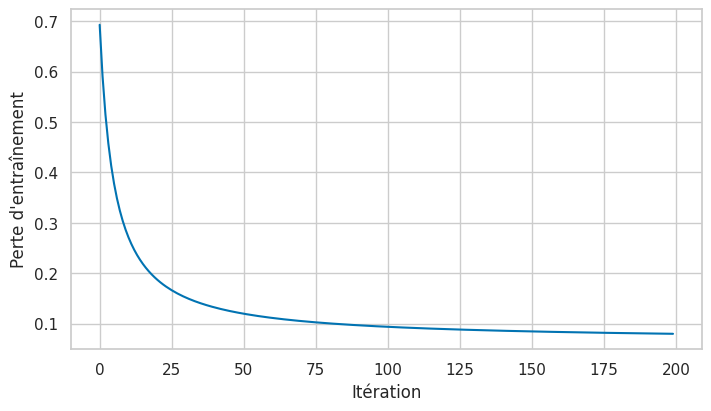

In [19]:
eta = 0.1              # le taux d'apprentissage
n_iterations = 200
losses = []

for t in range(n_iterations):
    y_hat = torch.sigmoid(X_train @ w + b)         # 1. passage avant
    loss = F.binary_cross_entropy(y_hat, y_train)  # 2. perte moyenne
    loss.backward()                                # 3. gradients
    with torch.no_grad():                          # 4. mise à jour
        w -= eta * w.grad
        b -= eta * b.grad
    w.grad.zero_()                                 # sinon les gradients
    b.grad.zero_()                                 # s'additionnent
    losses.append(loss.item())

fig, ax = plt.subplots(figsize=(7, 4), layout="constrained")
ax.plot(losses)
ax.set(xlabel="Itération", ylabel="Perte d'entraînement")
plt.show()

La perte descend vite, puis de plus en plus lentement : le neurone approche du minimum.

### Le taux d'apprentissage

Le taux d'apprentissage $\eta$ règle la taille des pas (cours 3). Pour comparer plusieurs valeurs, on range la boucle dans une fonction, `train_logistic_neuron`. Elle repart à chaque appel de paramètres nuls, et renvoie les paramètres entraînés et la liste des pertes :

In [20]:
def train_logistic_neuron(X, y, eta, n_iterations):
    """Entraîne un neurone logistique par descente du gradient.
    Renvoie les poids w, le biais b et la liste des pertes."""
    p = X.shape[1]
    w = torch.zeros(p, requires_grad=True, device=X.device)
    b = torch.zeros(1, requires_grad=True, device=X.device)
    losses = []
    for t in range(n_iterations):
        y_hat = torch.sigmoid(X @ w + b)               # 1. passage avant
        loss = F.binary_cross_entropy(y_hat, y)        # 2. perte moyenne
        loss.backward()                                # 3. gradients
        with torch.no_grad():                          # 4. mise à jour
            w -= eta * w.grad
            b -= eta * b.grad
        w.grad.zero_()
        b.grad.zero_()
        losses.append(loss.item())
    return w, b, losses

On compare quatre valeurs de $\eta$ sur 200 itérations :

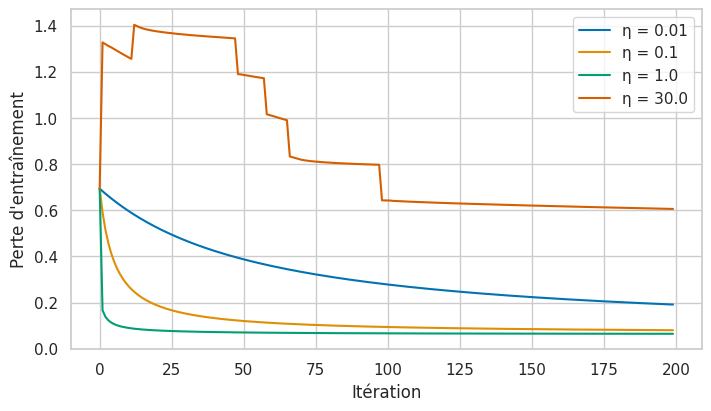

In [21]:
fig, ax = plt.subplots(figsize=(7, 4), layout="constrained")
for eta in [0.01, 0.1, 1.0, 30.0]:
    _, _, losses = train_logistic_neuron(X_train, y_train, eta, n_iterations=200)
    ax.plot(losses, label=f"η = {eta}")
ax.set(xlabel="Itération", ylabel="Perte d'entraînement")
ax.legend()
plt.show()

Avec $\eta = 0.01$, les pas sont trop petits : après 200 itérations, la perte est encore loin du minimum. Avec $\eta = 0.1$ et $\eta = 1$, elle converge, beaucoup plus vite avec 1. Avec $\eta = 30$, les pas sont trop grands : la perte remonte au-dessus de sa valeur de départ, et reste loin du minimum après 200 itérations.

### Évaluation sur le test

On garde $\eta = 1$, avec 2000 itérations pour converger complètement. Pour prédire, on calcule les probabilités du test sans suivre les gradients, et on prédit « malignant » quand la probabilité dépasse 0.5. `.cpu().numpy()` ramène le résultat en NumPy, pour les fonctions de mesure du TP 3.

In [22]:
w, b, losses = train_logistic_neuron(X_train, y_train, eta=1.0, n_iterations=2000)

with torch.no_grad():
    proba_test = torch.sigmoid(X_test @ w + b)
outputs_neuron_test = (proba_test > 0.5).int().cpu().numpy()

Les fonctions `compute_scores` et `plot_confusion` du TP 3 :

In [23]:
def compute_scores(outputs_true, outputs_pred, average="binary"):
    return {
        "Exactitude": accuracy_score(outputs_true, outputs_pred),
        "Précision": precision_score(outputs_true, outputs_pred,
                                     average=average, zero_division=0),
        "Rappel": recall_score(outputs_true, outputs_pred, average=average),
        "F1": f1_score(outputs_true, outputs_pred, average=average),
    }


def plot_confusion(outputs_true, outputs_pred):
    confusion = pd.crosstab(outputs_true, outputs_pred,
                            rownames=["Vraie classe"],
                            colnames=["Classe prédite"])
    fig, ax = plt.subplots(figsize=(4, 3), layout="constrained")
    sns.heatmap(confusion, annot=True, fmt="d", cmap="Blues", cbar=False, ax=ax)
    plt.show()

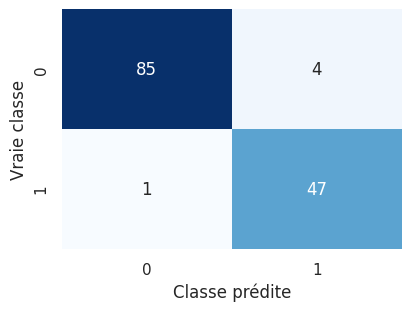

In [24]:
plot_confusion(outputs_test, outputs_neuron_test)

### Comparaison avec scikit-learn

La régression logistique de `scikit-learn` est régularisée par défaut. Avec un `C` très grand, la régularisation devient négligeable, car `C` est l'inverse de $\lambda$ (TP 3). Elle minimise alors la même perte que notre neurone, sur les mêmes données standardisées.

In [25]:
log_reg = LogisticRegression(C=1e6)
log_reg.fit(inputs_train_std, outputs_train)
outputs_log_test = log_reg.predict(inputs_test_std)

pd.DataFrame({"Neurone (PyTorch)": compute_scores(outputs_test, outputs_neuron_test),
              "Régression logistique (scikit-learn)":
                  compute_scores(outputs_test, outputs_log_test)}).T.round(3)

,Exactitude,Précision,Rappel,F1
Neurone (PyTorch),0.964,0.922,0.979,0.949
Régression logistique (scikit-learn),0.964,0.922,0.979,0.949


Les deux modèles obtiennent exactement les mêmes mesures sur le test. Comparons les paramètres eux-mêmes. `detach()` sépare `w` du suivi des gradients, avant sa conversion en NumPy.

In [26]:
parameters = pd.DataFrame({"Neurone (PyTorch)": w.detach().cpu().numpy(),
                           "Régression logistique (scikit-learn)": log_reg.coef_[0]},
                          index=inputs.columns)
parameters.loc["Biais"] = [b.item(), log_reg.intercept_[0]]
parameters.round(3)

,Neurone (PyTorch),Régression logistique (scikit-learn)
Cl.thickness,1.695,1.700
Cell.size,0.268,0.295
Cell.shape,0.641,0.602
Marg.adhesion,1.040,1.035
Epith.c.size,0.413,0.420
Bare.nuclei,2.212,2.215
Bl.cromatin,0.739,0.734
Normal.nucleoli,0.470,0.473
Mitoses,1.163,1.156
Biais,-0.940,-0.938


Les paramètres sont presque identiques : c'est le même modèle, trouvé par deux algorithmes différents. Les écarts les plus visibles portent sur `Cell.size` et `Cell.shape`, les deux mesures les plus corrélées (0.91) : on peut déplacer un peu de poids de l'une à l'autre sans presque changer la perte.

La semaine prochaine, PyTorch fera ces étapes pour nous, avec `nn.Module` et `torch.optim`, et nous pourrons empiler des couches.

---

## Exercice

Reprenez les données "PimaIndiansDiabetes.csv" de l'exercice du TP 3 : huit mesures, et la variable `diabetes`, qui vaut "pos" ou "neg". Il vous faut :

1. Charger les données, coder la sortie (1 pour "pos"), puis séparer un jeu d'entraînement et un jeu de test (20 %, stratifié, `random_state=42`).
2. Standardiser sans `StandardScaler` : transformer les variables d'entraînement et de test en tenseurs, calculer la moyenne et l'écart-type de chaque variable d'entraînement avec `mean(dim=0)` et `std(dim=0, correction=0)`, puis standardiser les deux jeux avec ces valeurs. Vérifier, en affichant le plus grand écart absolu, que le résultat est le même qu'avec `StandardScaler`.
3. Avec des paramètres nuls, calculer la perte, puis ses gradients avec `backward()`. Vérifier que `w.grad` est égal à $\frac{1}{n}\mathbf{X}^\top(\hat{\mathbf{y}} - \mathbf{y})$, calculé avec des opérations sur les tenseurs.
4. Entraîner le neurone avec la fonction `train_logistic_neuron`, en choisissant $\eta$ et le nombre d'itérations à l'aide des courbes de perte.
5. Évaluer le neurone sur le test, et le comparer à une régression logistique de `scikit-learn` avec `C=1e6` : mesures et paramètres.
6. Quelle variable a le plus grand poids ? Pourquoi peut-on comparer les poids des variables entre eux ?

In [27]:
data = pd.read_csv(data_path / "PimaIndiansDiabetes.csv")
data.head()

,pregnant,glucose,pressure,triceps,insulin,mass,pedigree,age,diabetes
0,6,148,72,35,0,33.6,0.627,50,pos
1,1,85,66,29,0,26.6,0.351,31,neg
2,8,183,64,0,0,23.3,0.672,32,pos
3,1,89,66,23,94,28.1,0.167,21,neg
4,0,137,40,35,168,43.1,2.288,33,pos
